<a href="https://colab.research.google.com/github/contreras-juan/procesamiento_lenguaje_natural/blob/main/Ejercicios/Soluciones/03_Taller_BoW_NGramas_Solucion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color: #FECB05; text-align: center;">Taller práctico: Bag-of-Words y N-gramas (solución)</h1>

<h2 style="color: #007ACC;">Autores</h2>

- [Juan Felipe Contreras Alcívar](https://www.linkedin.com/in/juanf-contreras/)

---

<h2 style="color: #007ACC;">Instrucciones</h2>

Solución de referencia del taller [`03_Taller_BoW_NGramas.ipynb`](../03_Taller_BoW_NGramas.ipynb).

Hay muchas soluciones válidas: esta es una de ellas. Compara tus resultados y, sobre todo, tus conclusiones.

<h2 style="color: #007ACC;">Tabla de contenido</h2>

- [<span style="color: #005C99;">Ejercicio 1. Dispersión y crecimiento del vocabulario</span>](#ejercicio-1)
- [<span style="color: #005C99;">Ejercicio 2. Modelo de bigramas con add-k y validación</span>](#ejercicio-2)
- [<span style="color: #005C99;">Ejercicio 3. Interpolación normalizada de trigramas</span>](#ejercicio-3)
- [<span style="color: #005C99;">Ejercicio 4. Autocompletado y generación con muestreo top-k</span>](#ejercicio-4)
- [<span style="color: #005C99;">Ejercicio 5. Atribución de autoría</span>](#ejercicio-5)

---

<h2 style="color: #007ACC;">Instalación de librerías</h2>

Ejecuta esta celda si trabajas en Google Colab o en un entorno nuevo.

In [1]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib nltk

Note: you may need to restart the kernel to use updated packages.


In [2]:
import math
import random
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.corpus import gutenberg
from nltk.classify import NaiveBayesClassifier, accuracy

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

_ = nltk.download("gutenberg", quiet=True)

LIBROS = {
    "austen": ["austen-emma.txt", "austen-persuasion.txt", "austen-sense.txt"],
    "chesterton": ["chesterton-ball.txt", "chesterton-brown.txt", "chesterton-thursday.txt"],
    "melville": ["melville-moby_dick.txt"],
}


def limpiar(oracion):
    """Minúsculas y solo tokens con alguna letra o signos de puntuación básicos."""
    return [w.lower() for w in oracion if any(c.isalpha() for c in w) or w in {".", ",", ";", "!", "?"}]


oraciones = {autor: [s for f in archivos for s in map(limpiar, gutenberg.sents(f)) if len(s) >= 3]
             for autor, archivos in LIBROS.items()}

# División 80/10/10 por autor (entrenamiento / validación / prueba)
particion = {}
for autor, sents in oraciones.items():
    sents = sents[:]
    random.Random(SEED).shuffle(sents)
    n = len(sents)
    particion[autor] = {"train": sents[:int(0.8 * n)], "dev": sents[int(0.8 * n):int(0.9 * n)],
                        "test": sents[int(0.9 * n):]}
    print(f"{autor:<11} {n:>6} oraciones")

austen       15810 oraciones
chesterton   11951 oraciones
melville      9408 oraciones


---

<a id="ejercicio-1"></a>
<h2 style="color: #007ACC;">Ejercicio 1. Dispersión y crecimiento del vocabulario</h2>

**Objetivo:** cuantificar cómo crece el número de N-gramas distintos con el tamaño del corpus y con $N$.

1. Implementa `ngramas(tokens, n)`.
2. Con las oraciones de **entrenamiento de Austen**, calcula para $N = 1, \dots, 4$ el número de N-gramas distintos y el porcentaje que aparece una sola vez. Presenta una tabla.
3. Grafica la **curva de crecimiento del vocabulario**: en el eje X el número de tokens leídos (recorriendo las oraciones en orden) y en el eje Y el número de unigramas distintos y de bigramas distintos vistos hasta ese momento. Usa escala log-log.
4. La **ley de Heaps** dice que el vocabulario crece como $V(n) \approx K n^{\beta}$ con $\beta < 1$. Estima $\beta$ para unigramas y bigramas ajustando una recta en escala log-log. ¿Qué significa que el vocabulario de bigramas crezca más rápido? ¿Qué implica para un modelo de trigramas?

In [3]:
def ngramas(tokens, n):
    return [tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]


austen_train = particion["austen"]["train"]
filas = []
for n in range(1, 5):
    conteo = Counter(g for s in austen_train for g in ngramas(s, n))
    filas.append({"N": n, "distintos": len(conteo), "% una sola vez": 100 * np.mean([c == 1 for c in conteo.values()])})
pd.DataFrame(filas).set_index("N").round(1)

,distintos,% una sola vez
N,,
1,9647,37.0
2,97135,68.3
3,214308,86.0
4,267933,95.2


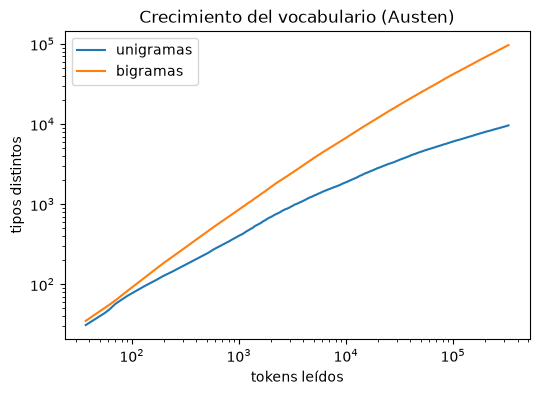

beta (unigramas) = 0.37
beta (bigramas) = 0.70


In [4]:
vistos_uni, vistos_bi = set(), set()
n_tokens, curva = 0, []
for s in austen_train:
    for w in s:
        vistos_uni.add(w)
    for g in ngramas(s, 2):
        vistos_bi.add(g)
    n_tokens += len(s)
    curva.append((n_tokens, len(vistos_uni), len(vistos_bi)))
curva = np.array(curva)

plt.figure(figsize=(6, 4))
plt.loglog(curva[:, 0], curva[:, 1], label="unigramas")
plt.loglog(curva[:, 0], curva[:, 2], label="bigramas")
plt.xlabel("tokens leídos")
plt.ylabel("tipos distintos")
plt.title("Crecimiento del vocabulario (Austen)")
plt.legend()
plt.show()

# Ajuste de la ley de Heaps sobre la segunda mitad de la curva (evita el régimen inicial)
mitad = len(curva) // 2
for col, nombre in [(1, "unigramas"), (2, "bigramas")]:
    beta, _ = np.polyfit(np.log(curva[mitad:, 0]), np.log(curva[mitad:, col]), 1)
    print(f"beta ({nombre}) = {beta:.2f}")

**Interpretación:**

- Más de la mitad de los bigramas y la gran mayoría de los trigramas y 4-gramas aparecen una sola vez: la dispersión crece rápidamente con $N$.
- El exponente $\beta$ de los bigramas es mayor que el de los unigramas: cada nuevo texto sigue aportando muchas **combinaciones** nuevas aunque ya casi no aporte palabras nuevas. Para los trigramas el efecto es aún mayor.
- Implicación: para estimar bien un modelo de trigramas se necesita un corpus mucho más grande que para uno de bigramas. Con datos limitados, la mayoría de los contextos de dos palabras que aparezcan en prueba serán nuevos, y el modelo tendrá que apoyarse en órdenes menores (suavizado, interpolación).

---

<a id="ejercicio-2"></a>
<h2 style="color: #007ACC;">Ejercicio 2. Modelo de bigramas con add-k y validación</h2>

**Objetivo:** implementar un modelo de bigramas con vocabulario cerrado y elegir $k$ con un conjunto de validación.

1. Construye el vocabulario `VOCAB` con las palabras que aparecen al menos 2 veces en el **entrenamiento de Austen**, más `<UNK>` y `</s>`. Implementa `unk(oracion)` que reemplace las palabras fuera del vocabulario por `<UNK>`.
2. Implementa la clase `BigramaAddK` con los métodos `entrenar(oraciones)`, `prob(palabra, previa)` y `log_prob(oracion)` (usa `<s>` al inicio y `</s>` al final).
3. Implementa `perplejidad(modelo, oraciones)`.
4. Evalúa $k \in \{1, 0.5, 0.1, 0.05, 0.01, 0.005, 0.001\}$ sobre el conjunto de **validación** de Austen y grafica la perplejidad contra $k$ (escala log en X).
5. Con el mejor $k$, reporta la perplejidad en **prueba**. ¿Por qué no elegimos $k$ directamente con el conjunto de prueba?

In [5]:
frec = Counter(w for s in austen_train for w in s)
VOCAB = {w for w, c in frec.items() if c >= 2} | {"<UNK>", "</s>"}


def unk(oracion):
    return [w if w in VOCAB else "<UNK>" for w in oracion]


A_train = [unk(s) for s in austen_train]
A_dev = [unk(s) for s in particion["austen"]["dev"]]
A_test = [unk(s) for s in particion["austen"]["test"]]
print(f"|V| = {len(VOCAB)}")


class BigramaAddK:
    def __init__(self, k):
        self.k = k

    def entrenar(self, oraciones):
        self.bi, self.uni = Counter(), Counter()
        for s in oraciones:
            tokens = ["<s>"] + s + ["</s>"]
            for a, b in zip(tokens, tokens[1:]):
                self.bi[(a, b)] += 1
                self.uni[a] += 1
        return self

    def prob(self, palabra, previa):
        return (self.bi[(previa, palabra)] + self.k) / (self.uni[previa] + self.k * len(VOCAB))

    def log_prob(self, oracion):
        tokens = ["<s>"] + oracion + ["</s>"]
        return sum(math.log(self.prob(b, a)) for a, b in zip(tokens, tokens[1:]))


def perplejidad(modelo, oraciones):
    log_p = sum(modelo.log_prob(s) for s in oraciones)
    return math.exp(-log_p / sum(len(s) + 1 for s in oraciones))

|V| = 6080


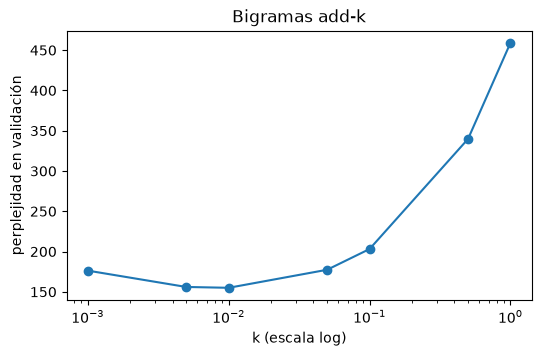

Mejor k = 0.01 | perplejidad en validación = 155.0 | en prueba = 160.2


In [6]:
ks = [1, 0.5, 0.1, 0.05, 0.01, 0.005, 0.001]
pp_dev = [perplejidad(BigramaAddK(k).entrenar(A_train), A_dev) for k in ks]

plt.figure(figsize=(6, 3.5))
plt.semilogx(ks, pp_dev, marker="o")
plt.xlabel("k (escala log)")
plt.ylabel("perplejidad en validación")
plt.title("Bigramas add-k")
plt.show()

mejor_k = ks[int(np.argmin(pp_dev))]
bigrama = BigramaAddK(mejor_k).entrenar(A_train)
print(f"Mejor k = {mejor_k} | perplejidad en validación = {min(pp_dev):.1f} | en prueba = {perplejidad(bigrama, A_test):.1f}")

**Interpretación:** la perplejidad tiene forma de U. Con $k = 1$ se reparte demasiada probabilidad entre los millones de bigramas posibles no vistos; con $k$ muy pequeño, los bigramas no vistos (que en prueba son muchos) reciben probabilidades minúsculas que penalizan mucho. Si eligiéramos $k$ mirando la prueba, la perplejidad reportada sería **optimista**: habríamos ajustado un hiperparámetro a esos datos y ya no medirían el desempeño sobre texto realmente nuevo.

---

<a id="ejercicio-3"></a>
<h2 style="color: #007ACC;">Ejercicio 3. Interpolación normalizada de trigramas</h2>

**Objetivo:** implementar una interpolación lineal que siempre sea una distribución de probabilidad válida y ajustar sus pesos en validación.

En el cuaderno 06, cuando un contexto no se había visto, su término de la interpolación simplemente no aportaba, así que las "probabilidades" no sumaban 1. Aquí lo haremos bien con una definición **recursiva**:

$$P_1(w) = \frac{C(w) + 1}{N + |V|}$$

$$P_2(w \mid u) = \begin{cases} \lambda_2 \, P_{\text{MLE}}(w \mid u) + (1 - \lambda_2)\, P_1(w) & \text{si } C(u) > 0 \\ P_1(w) & \text{si no} \end{cases}$$

$$P_3(w \mid u, v) = \begin{cases} \lambda_3 \, P_{\text{MLE}}(w \mid u, v) + (1 - \lambda_3)\, P_2(w \mid v) & \text{si } C(u, v) > 0 \\ P_2(w \mid v) & \text{si no} \end{cases}$$

1. Implementa la clase `TrigramaInterpolado(l2, l3)` con `entrenar`, `prob(palabra, u, v)` y `log_prob(oracion)` (usa dos `<s>` al inicio).
2. Comprueba numéricamente que, para un contexto cualquiera, $\sum_{w \in V} P_3(w \mid u, v) = 1$ (sin contar `<s>`, que nunca se predice).
3. Busca en una grilla $\lambda_2, \lambda_3 \in \{0.1, 0.3, 0.5, 0.7, 0.9\}$ la combinación con menor perplejidad en **validación**.
4. Compara en **prueba**: unigrama ($P_1$), bigrama add-k (ejercicio 2), bigrama interpolado ($\lambda_3 = 0$) y trigrama interpolado.

In [7]:
class TrigramaInterpolado:
    def __init__(self, l2, l3):
        self.l2, self.l3 = l2, l3

    def entrenar(self, oraciones):
        self.c1, self.c2, self.c3 = Counter(), Counter(), Counter()
        self.ctx1, self.ctx2 = Counter(), Counter()
        for s in oraciones:
            t = ["<s>", "<s>"] + s + ["</s>"]
            for i in range(2, len(t)):
                self.c1[t[i]] += 1
                self.c2[(t[i - 1], t[i])] += 1
                self.ctx1[t[i - 1]] += 1
                self.c3[(t[i - 2], t[i - 1], t[i])] += 1
                self.ctx2[(t[i - 2], t[i - 1])] += 1
        self.N = sum(self.c1.values())
        return self

    def p1(self, w):
        return (self.c1[w] + 1) / (self.N + len(VOCAB))

    def p2(self, w, v):
        if self.ctx1[v] == 0:
            return self.p1(w)
        return self.l2 * self.c2[(v, w)] / self.ctx1[v] + (1 - self.l2) * self.p1(w)

    def prob(self, w, u, v):
        if self.ctx2[(u, v)] == 0:
            return self.p2(w, v)
        return self.l3 * self.c3[(u, v, w)] / self.ctx2[(u, v)] + (1 - self.l3) * self.p2(w, v)

    def log_prob(self, oracion):
        t = ["<s>", "<s>"] + oracion + ["</s>"]
        return sum(math.log(self.prob(t[i], t[i - 2], t[i - 1])) for i in range(2, len(t)))


tri = TrigramaInterpolado(0.7, 0.5).entrenar(A_train)
for contexto in [("<s>", "<s>"), ("i", "am"), ("<UNK>", "zzz")]:
    print(contexto, f"suma = {sum(tri.prob(w, *contexto) for w in VOCAB):.6f}")

('<s>', '<s>') suma = 1.000000
('i', 'am') suma = 1.000000
('<UNK>', 'zzz') suma = 1.000000


In [8]:
grilla = [0.1, 0.3, 0.5, 0.7, 0.9]
res = {}
modelo = TrigramaInterpolado(0, 0).entrenar(A_train)  # los conteos no dependen de los lambdas
for l2 in grilla:
    for l3 in grilla:
        modelo.l2, modelo.l3 = l2, l3
        res[(l2, l3)] = perplejidad(modelo, A_dev)

tabla = pd.Series(res).unstack().round(1)
tabla.index.name, tabla.columns.name = "λ2", "λ3"
mejor_l2, mejor_l3 = min(res, key=res.get)
print(f"Mejores pesos: λ2 = {mejor_l2}, λ3 = {mejor_l3}")
tabla

Mejores pesos: λ2 = 0.7, λ3 = 0.3


λ3,0.1,0.3,0.5,0.7,0.9
λ2,,,,,
0.1,167.9,144.0,141.0,153.6,213.4
0.3,131.2,120.1,121.2,134.4,189.1
0.5,115.5,109.8,113.2,127.5,181.5
0.7,109.7,107.1,112.3,128.1,184.3
0.9,118.4,117.8,125.2,144.4,209.7


In [9]:
class Unigrama(TrigramaInterpolado):
    def prob(self, w, u, v):
        return self.p1(w)


bi_interp = TrigramaInterpolado(0, 0).entrenar(A_train)
bi_interp.l3 = 0.0
bi_interp.l2 = min(grilla, key=lambda l2: perplejidad(TrigramaInterpolado(l2, 0.0).entrenar(A_train), A_dev))
tri_final = TrigramaInterpolado(mejor_l2, mejor_l3).entrenar(A_train)

pd.Series({
    "unigrama (add-1)": perplejidad(Unigrama(0, 0).entrenar(A_train), A_test),
    f"bigrama add-k (k={mejor_k})": perplejidad(bigrama, A_test),
    f"bigrama interpolado (λ2={bi_interp.l2})": perplejidad(bi_interp, A_test),
    f"trigrama interpolado (λ2={mejor_l2}, λ3={mejor_l3})": perplejidad(tri_final, A_test),
}, name="perplejidad en prueba").round(1).to_frame()

,perplejidad en prueba
unigrama (add-1),370.7
bigrama add-k (k=0.01),160.2
bigrama interpolado (λ2=0.7),122.7
"trigrama interpolado (λ2=0.7, λ3=0.3)",109.9


**Interpretación:**

- La definición recursiva garantiza que cada distribución condicional suma 1, así que las perplejidades son comparables y honestas.
- La interpolación supera claramente al suavizado add-k: en lugar de repartir masa **uniformemente** entre las palabras no vistas en un contexto, la reparte según su frecuencia general (una palabra frecuente como *the* recibe más que una rara).
- Con interpolación, el trigrama sí mejora al bigrama: cuando el contexto de dos palabras es confiable lo aprovecha, y cuando no, se apoya en el bigrama.

---

<a id="ejercicio-4"></a>
<h2 style="color: #007ACC;">Ejercicio 4. Autocompletado y generación con muestreo top-k</h2>

**Objetivo:** usar el modelo de lenguaje para sugerir palabras y generar texto, controlando la diversidad.

1. Implementa `sugerir(prefijo, k=5)` que, dado un texto (por ejemplo `"she was very"`), devuelva las $k$ palabras más probables como continuación según el trigrama interpolado del ejercicio 3, con sus probabilidades. Excluye `<UNK>` de las sugerencias.
2. Pruébalo con al menos cuatro prefijos.
3. Implementa `generar(modelo, top_k, max_palabras=25)`: en cada paso calcula la distribución sobre todo el vocabulario, conserva solo las `top_k` palabras más probables (sin `<UNK>`), renormaliza y muestrea. Termina al generar `</s>`.
4. Genera tres oraciones con `top_k=1` (decodificación voraz), `top_k=10` y `top_k=200`. Describe las diferencias.

In [10]:
PALABRAS = sorted(VOCAB - {"<UNK>"})


def distribucion(modelo, u, v):
    return np.array([modelo.prob(w, u, v) for w in PALABRAS])


def sugerir(prefijo, k=5):
    tokens = ["<s>", "<s>"] + unk(prefijo.lower().split())
    p = distribucion(tri_final, tokens[-2], tokens[-1])
    mejores = np.argsort(-p)[:k]
    return [(PALABRAS[i], round(float(p[i]), 3)) for i in mejores]


for prefijo in ["she was very", "i am", "mr", "it is a truth universally"]:
    print(f"{prefijo!r:<30} -> {sugerir(prefijo)}")

'she was very'                 -> [('much', 0.089), ('well', 0.049), ('little', 0.021), ('good', 0.021), ('far', 0.017)]
'i am'                         -> [('sure', 0.209), ('not', 0.059), ('very', 0.046), ('afraid', 0.036), (',', 0.033)]
'mr'                           -> [('.', 0.668), ('elliot', 0.084), ('shepherd', 0.019), ('and', 0.017), (',', 0.013)]
'it is a truth universally'    -> [('a', 0.105), (';', 0.103), ('ill', 0.1), ('talked', 0.1), ('agreeable', 0.1)]


In [11]:
def generar(modelo, top_k, max_palabras=25, rng=None):
    rng = rng or np.random.default_rng()
    u, v, salida = "<s>", "<s>", []
    for _ in range(max_palabras):
        p = distribucion(modelo, u, v)
        candidatos = np.argsort(-p)[:top_k]
        pk = p[candidatos] / p[candidatos].sum()
        w = PALABRAS[candidatos[rng.choice(len(candidatos), p=pk)]]
        if w == "</s>":
            break
        salida.append(w)
        u, v = v, w
    return " ".join(salida)


rng = np.random.default_rng(SEED)
for top_k in [1, 10, 200]:
    print(f"--- top_k = {top_k} ---")
    for _ in range(3):
        print("  " + generar(tri_final, top_k, rng=rng))

--- top_k = 1 ---
  i am sure i have been a very good sort of the house , and the same time , and the same time , and
  i am sure i have been a very good sort of the house , and the same time , and the same time , and
  i am sure i have been a very good sort of the house , and the same time , and the same time , and
--- top_k = 10 ---


  she had a little .


  he would be a very few minutes , however , was the most natural to pay her respects irreproachable , i have , somehow or
  he had been to see him , but i cannot recollect that her sister .
--- top_k = 200 ---
  i can be supposed that any thing like it out again , with a direction , her own doing something concerning all that was quite
  no longer . and while the .


  yes , who but was really beloved by the good deal in i shall his of what had half a minute of ever drawing near


**Interpretación:**

- Con `top_k=1` (voraz) el resultado es **determinista**: las tres oraciones son idénticas y el texto entra en un bucle (*"and the same time , and the same time..."*), porque desde un mismo contexto siempre se elige la misma continuación.
- Con `top_k=10` el texto es variado y localmente fluido, con el tono de una novela de Austen, aunque sin coherencia global.
- Con `top_k=200` aparecen continuaciones poco probables y el texto se vuelve errático y agramatical.
- En las sugerencias, *mr* va seguido casi siempre de `.`: el tokenizador separa el punto de la abreviatura *Mr.*, un detalle del preprocesamiento que el modelo aprende tal cual.
- Los grandes modelos de lenguaje usan exactamente estas estrategias de muestreo (voraz, *top-k*, *top-p*, temperatura) sobre distribuciones mucho mejores.

---

<a id="ejercicio-5"></a>
<h2 style="color: #007ACC;">Ejercicio 5. Atribución de autoría</h2>

**Objetivo:** clasificar oraciones por autor con modelos de lenguaje (un clasificador generativo) y compararlo con Naive Bayes de NLTK.

Un modelo de lenguaje por clase es un **clasificador generativo**: asignamos la oración al autor cuyo modelo le da mayor probabilidad (con priors iguales):

$$\hat{a} = \arg\max_{a} P_a(\text{oración})$$

1. Construye un vocabulario **común** con las palabras que aparecen al menos 2 veces en el entrenamiento de **todos** los autores juntos (así las probabilidades de los distintos modelos son comparables).
2. Entrena un `TrigramaInterpolado` por autor (puedes usar $\lambda_2 = 0.7$, $\lambda_3 = 0.5$ o los mejores del ejercicio 3).
3. Clasifica las oraciones de **prueba** de los tres autores y reporta la exactitud global y la matriz de confusión.
4. Entrena un `NaiveBayesClassifier` de NLTK con características `contiene(palabra)` para las 2 000 palabras más frecuentes y compáralo.
5. Agrupa las oraciones de prueba por longitud (por ejemplo: 3–8, 9–15, 16–30, más de 30 tokens) y grafica la exactitud de ambos métodos por grupo. Interpreta.

In [12]:
frec_todos = Counter(w for a in LIBROS for s in particion[a]["train"] for w in s)
VOCAB = {w for w, c in frec_todos.items() if c >= 2} | {"<UNK>", "</s>"}  # sustituye al de Austen


modelos = {a: TrigramaInterpolado(0.7, 0.5).entrenar([unk(s) for s in particion[a]["train"]]) for a in LIBROS}

prueba = [(s, a) for a in LIBROS for s in particion[a]["test"]]
reales = [a for _, a in prueba]
pred_lm = [max(modelos, key=lambda m: modelos[m].log_prob(unk(s))) for s, _ in prueba]
print(f"Exactitud (modelos de lenguaje): {np.mean(np.array(pred_lm) == np.array(reales)):.3f}")
print(pd.crosstab(pd.Series(reales, name="real"), pd.Series(pred_lm, name="predicho")))

Exactitud (modelos de lenguaje): 0.901
predicho    austen  chesterton  melville
real                                    
austen        1498          54        29
chesterton     104        1030        62
melville        50          68       823


In [13]:
frec_nb = Counter(w for a in LIBROS for s in particion[a]["train"] for w in s)
TOP = {w for w, _ in frec_nb.most_common(2000)}


def feats(s):
    return {f"contiene({w})": True for w in s if w in TOP}


nb = NaiveBayesClassifier.train([(feats(s), a) for a in LIBROS for s in particion[a]["train"]])
pred_nb = [nb.classify(feats(s)) for s, _ in prueba]
print(f"Exactitud (Naive Bayes de NLTK): {np.mean(np.array(pred_nb) == np.array(reales)):.3f}")
nb.show_most_informative_features(10)

Exactitud (Naive Bayes de NLTK): 0.772
Most Informative Features
         contiene(whale) = True           melvil : cheste =    733.8 : 1.0
          contiene(miss) = True           austen : melvil =    259.6 : 1.0
          contiene(thou) = True           melvil : austen =    223.5 : 1.0
          contiene(anne) = True           austen : melvil =    150.9 : 1.0
          contiene(deck) = True           melvil : cheste =    125.8 : 1.0
       contiene(herself) = True           austen : melvil =    122.2 : 1.0
          contiene(ship) = True           melvil : austen =    101.5 : 1.0
         contiene(boats) = True           melvil : cheste =     97.8 : 1.0
          contiene(boat) = True           melvil : austen =     93.2 : 1.0
           contiene(mrs) = True           austen : cheste =     87.4 : 1.0


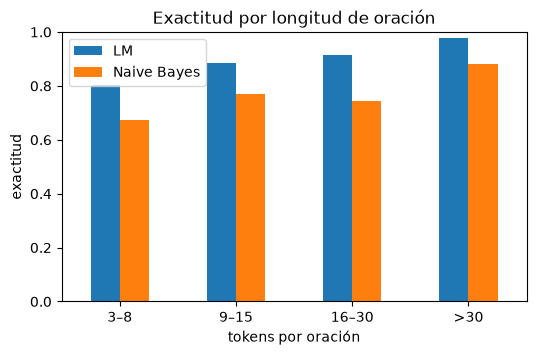

,LM,Naive Bayes
grupo,,
3–8,0.803,0.673
9–15,0.884,0.768
16–30,0.913,0.743
>30,0.976,0.882


In [14]:
longitudes = np.array([len(s) for s, _ in prueba])
grupos = pd.cut(longitudes, bins=[2, 8, 15, 30, 1000], labels=["3–8", "9–15", "16–30", ">30"])
df = pd.DataFrame({"grupo": grupos, "LM": np.array(pred_lm) == np.array(reales),
                   "Naive Bayes": np.array(pred_nb) == np.array(reales)})
por_grupo = df.groupby("grupo", observed=True)[["LM", "Naive Bayes"]].mean()
por_grupo.plot.bar(rot=0, figsize=(6, 3.5), ylim=(0, 1), title="Exactitud por longitud de oración")
plt.xlabel("tokens por oración")
plt.ylabel("exactitud")
plt.show()
por_grupo.round(3)

**Interpretación:**

- Ambos enfoques están muy por encima del azar (33 %), pero los modelos de lenguaje superan a Naive Bayes por más de 10 puntos. Naive Bayes solo mira qué palabras frecuentes están presentes, y sus características más informativas son temáticas (*whale*, *deck*, *ship* en Melville; *miss*, *mrs*, *herself* en Austen). Los modelos de lenguaje usan todas las palabras del vocabulario y, además, el **orden**: las combinaciones de palabras típicas del estilo de cada autor.
- Las **oraciones cortas** son mucho más difíciles para ambos métodos: con 3–8 palabras hay muy poca evidencia, y muchas oraciones cortas (*"i do not know."*) podrían ser de cualquiera de los autores. Con oraciones de más de 30 palabras, los modelos de lenguaje aciertan en casi el 98 % de los casos.
- Advertencia metodológica: dividimos las oraciones al azar, así que oraciones de prueba y de entrenamiento comparten **libros** y nombres de personajes. Una evaluación más exigente (y más realista) entrenaría con unos libros y probaría con otros del mismo autor.

<a id="referencias"></a>
<h2 style="color: #007ACC;">Referencias</h2>

- Jurafsky, D. & Martin, J. H. *Speech and Language Processing* (3.ª ed. borrador). [web.stanford.edu/~jurafsky/slp3](https://web.stanford.edu/~jurafsky/slp3/)
- Bird, S., Klein, E. & Loper, E. (2009). *Natural Language Processing with Python*. O'Reilly Media. [nltk.org/book](https://www.nltk.org/book/)
- Heaps, H. S. (1978). *Information Retrieval: Computational and Theoretical Aspects*. Academic Press.
- Stamatatos, E. (2009). A survey of modern authorship attribution methods. *JASIST*, 60(3).